# Part 1: measured comparison across all five models
Run after the five executed model notebooks are available. This notebook reads the structured outputs embedded in those notebooks; it does not use a hand-entered score table. Missing results are displayed as missing. The comparisons check total/active parameters, tokenizer, dataset revision, exact training schedule, token budgets and BLEU samples before ranking models.

A single seed, short learning-rate pilots, one generation strategy and a 1,000-triplet BLEU sample limit the conclusions. Confidence intervals describe sample variation only. Validation data choose learning rate; test data are used for the final measurements. The assigned writeup must be your own work.


In [1]:
from pathlib import Path
import json, os
here=Path.cwd().resolve()
ROOT=next((p for p in [here,*here.parents,here/'part 1'] if (p/'shared'/'implementation.ipynb').exists()),None)
assert ROOT is not None, 'Set the notebook working directory inside part 1.'
for cell in json.loads((ROOT/'shared'/'implementation.ipynb').read_text())['cells']:
    if cell['cell_type']=='code' and 'definitions' in cell.get('metadata',{}).get('tags',[]):
        exec(compile(cell['source'],'shared/implementation.ipynb','exec'),globals())


In [2]:
results=[]; missing=[]
for i in range(1,6):
    paths=[ROOT/f'model {i}'/f'model_{i}.ipynb']
    found=None
    for path in paths:
        if not path.exists(): continue
        notebook=json.loads(path.read_text())
        for cell in notebook['cells']:
            if 'part1-result' not in cell.get('metadata',{}).get('tags',[]): continue
            for output in cell.get('outputs',[]):
                candidate=output.get('data',{}).get('application/json')
                if candidate and candidate.get('status')=='full run completed': found=candidate
        if found: break
    if found: results.append(found)
    else: missing.append(i)
print('Missing full-run results:',missing)
if results:
    table=pd.DataFrame([{'Model':r['model'],'Total parameters':r['parameters']['total'],'Active min':r['parameters']['active_min'],'Active max':r['parameters']['active_max'],
                         'Input tokens':r['training']['input_tokens'],'Target tokens':r['training']['target_tokens'],'Selected LR':r['config']['lr'],
                         'Test perplexity':r['test']['ppl'],'PPL vi':r['test']['ppl_vi'],'PPL ja':r['test']['ppl_ja'],
                         'BLEU':r['bleu']['bleu'],'BLEU vi':r['bleu']['bleu_vi'],'BLEU ja':r['bleu']['bleu_ja'],
                         'Training minutes':r['training']['seconds']/60} for r in results]).set_index('Model')
    display(table)
    for getter in [lambda r:r['training']['schedule_digest'],lambda r:r['training']['input_tokens'],lambda r:r['training']['target_tokens'],lambda r:r['tokenizer_sha256'],lambda r:r['dataset_revision'],lambda r:r['bleu']['sample_rows_sha256']]:
        assert len({getter(r) for r in results})==1, 'Unfair or incompatible experiment inputs'
    by_model={r['model']:r for r in results}
    assert len({r['parameters']['total'] for r in results if r['model']<=4})<=1
    if 1 in by_model and 5 in by_model:
        assert by_model[1]['parameters']['total']==by_model[5]['parameters']['active_min']==by_model[5]['parameters']['active_max']
    print('Fairness checks passed for available results. All five complete:',not missing)


Missing full-run results: []


,Total parameters,Active min,Active max,Input tokens,Target tokens,Selected LR,Test perplexity,PPL vi,PPL ja,BLEU,BLEU vi,BLEU ja,Training minutes
Model,,,,,,,,,,,,,
1,27079680,27079680,27079680,59998213,29239313,0.0006,5.244681,4.450996,6.179894,35.133571,41.081240,29.054448,11.648083
2,27079680,17648640,17654784,59998213,29239313,0.0006,5.355744,4.567268,6.280340,34.830208,40.549548,28.973651,17.603062
3,27079680,20788224,20800512,59998213,29239313,0.0006,5.338887,4.523463,6.301304,34.453895,40.038555,28.757970,17.093885
4,27079680,20794368,20800512,59998213,29239313,0.0006,5.380499,4.559601,6.349189,34.849988,40.696013,28.876515,17.062072
5,39650304,27079680,27079680,59998213,29239313,0.0006,5.164709,4.387460,6.079649,35.377462,40.667292,29.993694,17.469979


Fairness checks passed for available results. All five complete: True


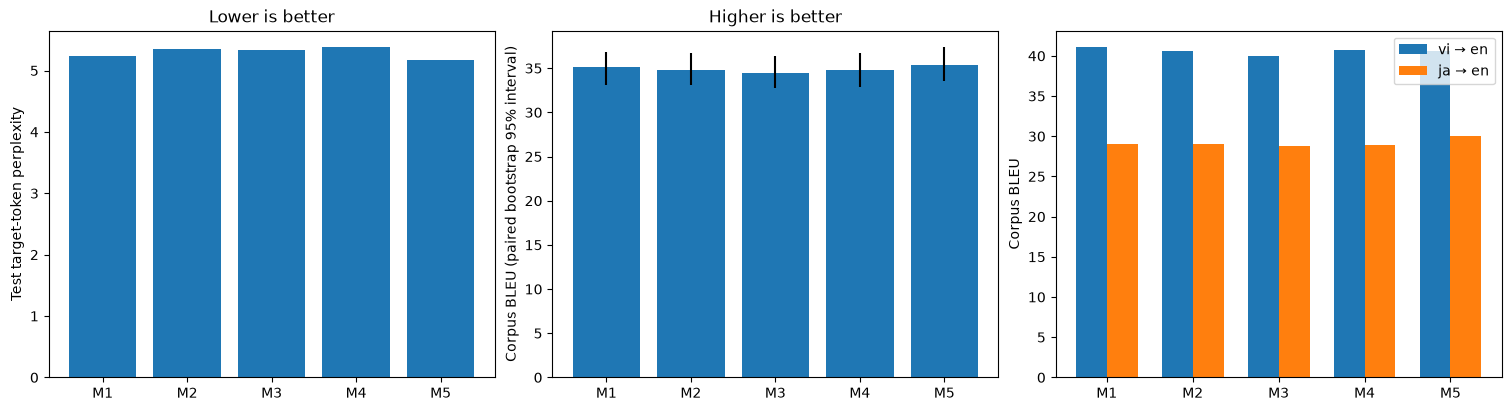

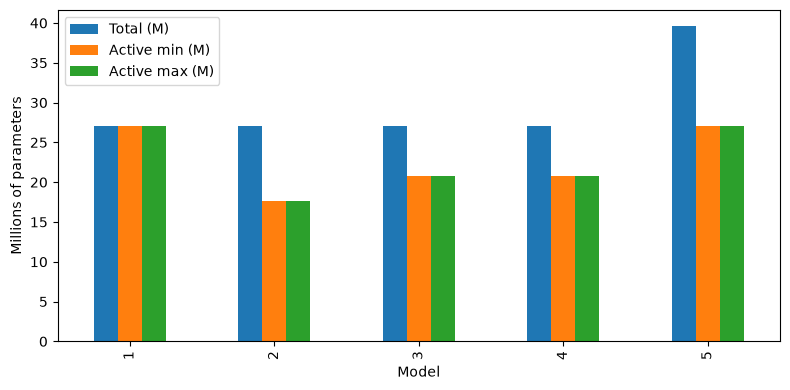

In [3]:
if results:
    fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
    labels=[f'M{r["model"]}' for r in results]; positions=np.arange(len(results))
    axes[0].bar(labels,[r['test']['ppl'] for r in results]); axes[0].set(ylabel='Test target-token perplexity',title='Lower is better')
    values=np.array([r['bleu']['bleu'] for r in results]); intervals=np.array([r['bleu']['bleu_ci95'] for r in results])
    # Percentile intervals are drawn as endpoints, without assuming they contain the estimate.
    axes[1].bar(labels,values); axes[1].vlines(positions,intervals[:,0],intervals[:,1],color='black'); axes[1].set(ylabel='Corpus BLEU (paired bootstrap 95% interval)',title='Higher is better')
    axes[2].bar(positions-.18,[r['bleu']['bleu_vi'] for r in results],width=.36,label='vi → en')
    axes[2].bar(positions+.18,[r['bleu']['bleu_ja'] for r in results],width=.36,label='ja → en')
    axes[2].set(xticks=positions,xticklabels=labels,ylabel='Corpus BLEU'); axes[2].legend(); plt.show()
    capacities=pd.DataFrame([{'Model':r['model'],'Total (M)':r['parameters']['total']/1e6,'Active min (M)':r['parameters']['active_min']/1e6,'Active max (M)':r['parameters']['active_max']/1e6} for r in results]).set_index('Model')
    capacities.plot.bar(figsize=(8,4),ylabel='Millions of parameters'); plt.tight_layout(); plt.show()


In [4]:
# Paired bootstrap of each model's BLEU difference from the baseline.
if results and any(r['model']==1 for r in results):
    baseline=next(r for r in results if r['model']==1)
    metric=sacrebleu.metrics.BLEU(); paired=[]; n=baseline['bleu']['triplets']; rng=np.random.default_rng(777)
    samples=[rng.integers(0,n,n) for _ in range(300)]
    base_records=baseline['predictions']
    def resampled_score(records,ix):
        sampled=[records[int(i)+offset] for offset in (0,n) for i in ix]
        return metric.corpus_score([r['hypothesis'] for r in sampled],[[r['reference'] for r in sampled]]).score
    base_scores=np.array([resampled_score(base_records,ix) for ix in samples])
    for r in results:
        if r['model']==1: continue
        assert [(p['row'],p['language'],p['reference']) for p in r['predictions']]==[(p['row'],p['language'],p['reference']) for p in base_records]
        differences=np.array([resampled_score(r['predictions'],ix) for ix in samples])-base_scores
        low,high=np.percentile(differences,[2.5,97.5])
        paired.append({'Model':r['model'],'BLEU minus M1':r['bleu']['bleu']-baseline['bleu']['bleu'],'paired CI low':low,'paired CI high':high,'CI contains zero':bool(low<=0<=high)})
    display(pd.DataFrame(paired))


,Model,BLEU minus M1,paired CI low,paired CI high,CI contains zero
0,2,-0.303363,-0.986947,0.450020,True
1,3,-0.679676,-1.333982,0.147617,True
2,4,-0.283583,-0.953407,0.524275,True
3,5,0.243891,-0.344550,1.019503,True


In [5]:
if results:
    # Show the same sentences across models, including the lowest sentence-BLEU cases.
    records=pd.concat([pd.DataFrame(r['predictions']).assign(model=r['model']) for r in results],ignore_index=True)
    records['sentence_BLEU']=records.apply(lambda r:sacrebleu.sentence_bleu(r.hypothesis,[r.reference]).score,axis=1)
    display(records.groupby(['model','language']).agg(cap_hits=('capped','sum'),sentences=('row','count'),mean_sentence_BLEU=('sentence_BLEU','mean')))
    difficult=records.groupby(['row','language']).sentence_BLEU.mean().nsmallest(5).index
    display(records.set_index(['row','language']).loc[difficult,['model','source','reference','hypothesis','sentence_BLEU']])
    print('Mean sentence BLEU is a diagnostic only; the assignment score is corpus BLEU.')
    status=pd.DataFrame([{'Model':r['model'],'Full run':True,'Checkpoint verified locally':(ROOT/r['checkpoint']).exists() and sha(ROOT/r['checkpoint'])==r['checkpoint_sha256'],'Hugging Face link':r.get('huggingface_url','NOT UPLOADED')} for r in results])
    display(status)
else:
    print('No completed experiments are available. No performance ranking can be made.')


cap_hits  sentences  mean_sentence_BLEU
model language                                         
1     ja               5       1000           33.369839
      vi               1       1000           41.877869
2     ja               0       1000           33.031513
      vi               0       1000           41.280075
3     ja               0       1000           32.715104
      vi               1       1000           40.723499
4     ja               0       1000           33.394498
      vi               1       1000           41.275768
5     ja               0       1000           33.988602
      vi               1       1000           41.141361

model                               source  \
row  language                                               
2266 vi            1                 Máy ảo dựa trên UEFI   
     vi            2                 Máy ảo dựa trên UEFI   
     vi            3                 Máy ảo dựa trên UEFI   
     vi            4                 Máy ảo dựa trên UEFI   
     vi            5                 Máy ảo dựa trên UEFI   
4394 ja            1              ザ· ベスト Krystal 盗む Fuck1   
     ja            2              ザ· ベスト Krystal 盗む Fuck1   
     ja            3              ザ· ベスト Krystal 盗む Fuck1   
     ja            4              ザ· ベスト Krystal 盗む Fuck1   
     ja            5              ザ· ベスト Krystal 盗む Fuck1   
     vi            1    Các Tốt nhất Krystal Ăn cắp Fuck1   
     vi            2    Các Tốt nhất Krystal Ăn cắp Fuck1   
     vi            3    Các Tốt nhất Krystal Ăn cắp Fuck1   
     vi            4    Các Tốt nhất Krystal Ăn cắp Fuck1   
     vi            5    Các Tốt nhất Krystal Ăn cắp Fuck1   
8651 ja            1                          死亡または重傷のリスク   
     ja            2                          死亡または重傷のリスク   
     ja            3                          死亡または重傷のリスク   
     ja            4                          死亡または重傷のリスク   
     ja            5                          死亡または重傷のリスク   
     vi            1  Nguy cơ tử vong hoặc bị thương nặng   
     vi            2  Nguy cơ tử vong hoặc bị thương nặng   
     vi            3  Nguy cơ tử vong hoặc bị thương nặng   
     vi            4  Nguy cơ tử vong hoặc bị thương nặng   
     vi            5  Nguy cơ tử vong hoặc bị thương nặng   

                                     reference  \
row  language                                    
2266 vi            UEFI-based virtual machines   
     vi            UEFI-based virtual machines   
     vi            UEFI-based virtual machines   
     vi            UEFI-based virtual machines   
     vi            UEFI-based virtual machines   
4394 ja           THE BEST KRYSTAL STEAL FUCK1   
     ja           THE BEST KRYSTAL STEAL FUCK1   
     ja           THE BEST KRYSTAL STEAL FUCK1   
     ja           THE BEST KRYSTAL STEAL FUCK1   
     ja           THE BEST KRYSTAL STEAL FUCK1   
     vi           THE BEST KRYSTAL STEAL FUCK1   
     vi           THE BEST KRYSTAL STEAL FUCK1   
     vi           THE BEST KRYSTAL STEAL FUCK1   
     vi           THE BEST KRYSTAL STEAL FUCK1   
     vi           THE BEST KRYSTAL STEAL FUCK1   
8651 ja        RISK OF DEATH OR SERIOUS INJURY   
     ja        RISK OF DEATH OR SERIOUS INJURY   
     ja        RISK OF DEATH OR SERIOUS INJURY   
     ja        RISK OF DEATH OR SERIOUS INJURY   
     ja        RISK OF DEATH OR SERIOUS INJURY   
     vi        RISK OF DEATH OR SERIOUS INJURY   
     vi        RISK OF DEATH OR SERIOUS INJURY   
     vi        RISK OF DEATH OR SERIOUS INJURY   
     vi        RISK OF DEATH OR SERIOUS INJURY   
     vi        RISK OF DEATH OR SERIOUS INJURY   

                                      hypothesis  sentence_BLEU  
row  language                                                    
2266 vi            Virtual machine based on UEFI            0.0  
     vi            Virtual machine based on UEFI            0.0  
     vi            Virtual machine based on UEFI            0.0  
     vi            Virtual machine based on UEFI            0.0  
     vi            Virtual Machine based on UEFI            0.0  
4394 ja           The Best Krystal Stomach Fuck1            0.0  
     ja            The Best Krystal Stolen Fuck1            0.0  
     ja           The Best Krystal Strings Fuck1            0.0  
     ja            The Best Krystal Stolen Fuck1            0.0  
     ja             The Best Krystal Steal Fuck1            0.0  
     vi               The Best Krystal Eat Fuck1            0.0  
     vi         The Best Krystal Vegetable Fuck1            0.0  
     vi         The Best Krystal Vegetable Fuck1            0.0  
     vi               The 

Mean sentence BLEU is a diagnostic only; the assignment score is corpus BLEU.


,Model,Full run,Checkpoint verified locally,Hugging Face link
0,1,True,True,NOT UPLOADED
1,2,True,True,NOT UPLOADED
2,3,True,True,NOT UPLOADED
3,4,True,True,NOT UPLOADED
4,5,True,True,NOT UPLOADED
